# Notebook 3b: Explaining the Embedding Model with SHAP

Notebook 02b showed that **BGE sentence embeddings + Logistic Regression** classify much better than TF-IDF (macro F1 0.81 vs 0.59).
This notebook explains *why* it predicts what it predicts, using SHAP, the same way notebook 03 did for the TF-IDF model.

**The challenge.** The BGE model sees a 768-number vector, not words. SHAP values for "dimension 412" would mean nothing to a support agent.
So we explain the **whole pipeline** (text → BGE → Logistic Regression) in terms of the **words** of the message:

- A "player" in the Shapley game is one word of the message.
- Leaving a word out means **deleting it from the sentence** and embedding the shorter sentence again.
- The value being explained is the model's **score (logit) for each category**, the same quantity notebook 03 explains.
- The starting point (base value) is the score of an empty message.

Messages are short (8 to 14 words), so we can try **every** subset of words and get **exact** Shapley values, not an approximation.
Like in notebook 03, the values add up exactly: base value + sum of word contributions = the model's score. We check this below.

**Requirements:** `sentence-transformers` (same as notebook 02b) and `models/bge_logreg.joblib` from notebook 02b. The `shap` library is optional (cross-check only).
**Runtime:** about 5 minutes on an Apple-silicon GPU, about 12 minutes on CPU (around 270,000 short sentences to embed).

In [1]:
import os
os.environ.update(HF_HUB_DISABLE_PROGRESS_BARS="1", TRANSFORMERS_VERBOSITY="error", TQDM_DISABLE="1")
import sys
import re
import json
import time
import logging
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
logging.disable(logging.WARNING)   # hide torch / Hugging Face start-up notices
from math import factorial
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

TEXT, TARGET, SEED = config.TEXT, config.TARGET, config.SEED
FIG = config.FIGURES

bundle = joblib.load(config.MODELS / "bge_logreg.joblib")
clf = bundle["classifier"]
classes = list(clf.classes_)
device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
encoder = SentenceTransformer(bundle["encoder"], device=device)

tickets = pd.read_csv(config.PROCESSED / "tickets_clean.csv")
unique = tickets.groupby([TEXT, TARGET]).size().rename("tickets").reset_index()
print("Encoder:", bundle["encoder"], "on", device)
print("Classes:", classes)
print("Unique messages:", len(unique), "| words per message:", unique[TEXT].str.split().str.len().min(), "to",
      unique[TEXT].str.split().str.len().max())

Encoder: BAAI/bge-base-en-v1.5 on mps
Classes: ['account_access', 'billing_problem', 'bug', 'feature_request', 'how_to', 'other', 'performance', 'security_concern']
Unique messages: 96 | words per message: 8 to 14


## 1. Calculate exact word-level SHAP values

For a message with *n* words we score all 2<sup>n</sup> versions of it (every combination of words kept or deleted) and apply the Shapley formula:

`SHAP(word) = Σ over subsets S without the word: weight(|S|) × [ score(S + word) − score(S) ]`, with `weight(s) = s! (n − s − 1)! / n!`

Every shortened sentence is embedded once and remembered, because many of them repeat across messages (for example the 7 product versions of a sentence share most subsets).

In [2]:
score_cache = {}

def scores(texts):
    """Model score (logit) for every category, for a list of texts. Each distinct text is embedded only once."""
    new = [t for t in dict.fromkeys(texts) if t not in score_cache]
    if new:
        emb = encoder.encode(new, batch_size=256, normalize_embeddings=True, show_progress_bar=False)
        score_cache.update(zip(new, clf.decision_function(emb)))
    return np.array([score_cache[t] for t in texts])

def exact_shap(text):
    """Exact Shapley value of every word, for every category. Returns words, values (words x classes), base and full scores."""
    words = text.split()
    n = len(words)
    masks = np.arange(2 ** n)                                  # bit j = 1 means word j is kept
    V = scores([" ".join(w for j, w in enumerate(words) if m >> j & 1) for m in masks])
    size = np.array([bin(m).count("1") for m in masks])
    weight = np.array([factorial(s) * factorial(n - s - 1) / factorial(n) for s in range(n)])
    phi = np.zeros((n, len(classes)))
    for j in range(n):
        without = masks[(masks >> j) & 1 == 0]
        phi[j] = (weight[size[without]][:, None] * (V[without | (1 << j)] - V[without])).sum(axis=0)
    return words, phi, V[0], V[-1]

def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

start = time.time()
results = []
for text in unique[TEXT]:
    words, phi, base, full = exact_shap(text)
    proba = softmax(full)
    results.append({"words": words, "phi": phi, "base": base, "full": full,
                    "pred": classes[int(proba.argmax())], "confidence": proba.max()})
print(f"Explained {len(results)} messages in {time.time() - start:.0f}s ({len(score_cache):,} distinct sentences embedded)")

Explained 96 messages in 246s (212,596 distinct sentences embedded)


In [3]:
# Check 1: base value + sum of word SHAP values = model score, for every message and category
err = max(np.abs(r["base"] + r["phi"].sum(axis=0) - r["full"]).max() for r in results)
print(f"Largest difference between SHAP total and model score: {err:.1e}")

# Check 2: the explained scores give the same predictions as the saved model
direct = clf.predict(encoder.encode(unique[TEXT].tolist(), normalize_embeddings=True, show_progress_bar=False))
print("Predictions match the model:", all(r["pred"] == d for r, d in zip(results, direct)))

Largest difference between SHAP total and model score: 3.6e-08


Predictions match the model: True


**Optional cross-check with the `shap` library.** `shap.explainers.Exact` computes exact Shapley values for any function. We give it the same
"keep / delete each word" switches and compare on a few messages. If `shap` isn't installed the cell just says so.

In [4]:
try:
    import shap
    diffs = []
    for i in [0, 40, 80]:
        words = results[i]["words"]
        f = lambda M, words=words: scores([" ".join(w for w, keep in zip(words, row) if keep) for row in M.astype(bool)])
        lib = shap.explainers.Exact(f, shap.maskers.Independent(np.zeros((1, len(words)))))(np.ones((1, len(words))))
        diffs.append(np.abs(np.array(lib.values[0]) - results[i]["phi"]).max())
    print(f"shap {shap.__version__} installed. Largest difference from our values on 3 messages: {max(diffs):.1e}")
except ImportError:
    print("shap is not installed; skipping the cross-check (our exact calculation is used).")

shap 0.54.1 installed. Largest difference from our values on 3 messages: 1.1e-08


## 2. Global view: which words drive each category?

Same method as notebook 03: for each category we average the SHAP values (towards that category) over the category's tickets, weighted by how many tickets use each sentence.
Words are lower-cased and stripped of punctuation, so "attempts." and "attempts" count as one word.

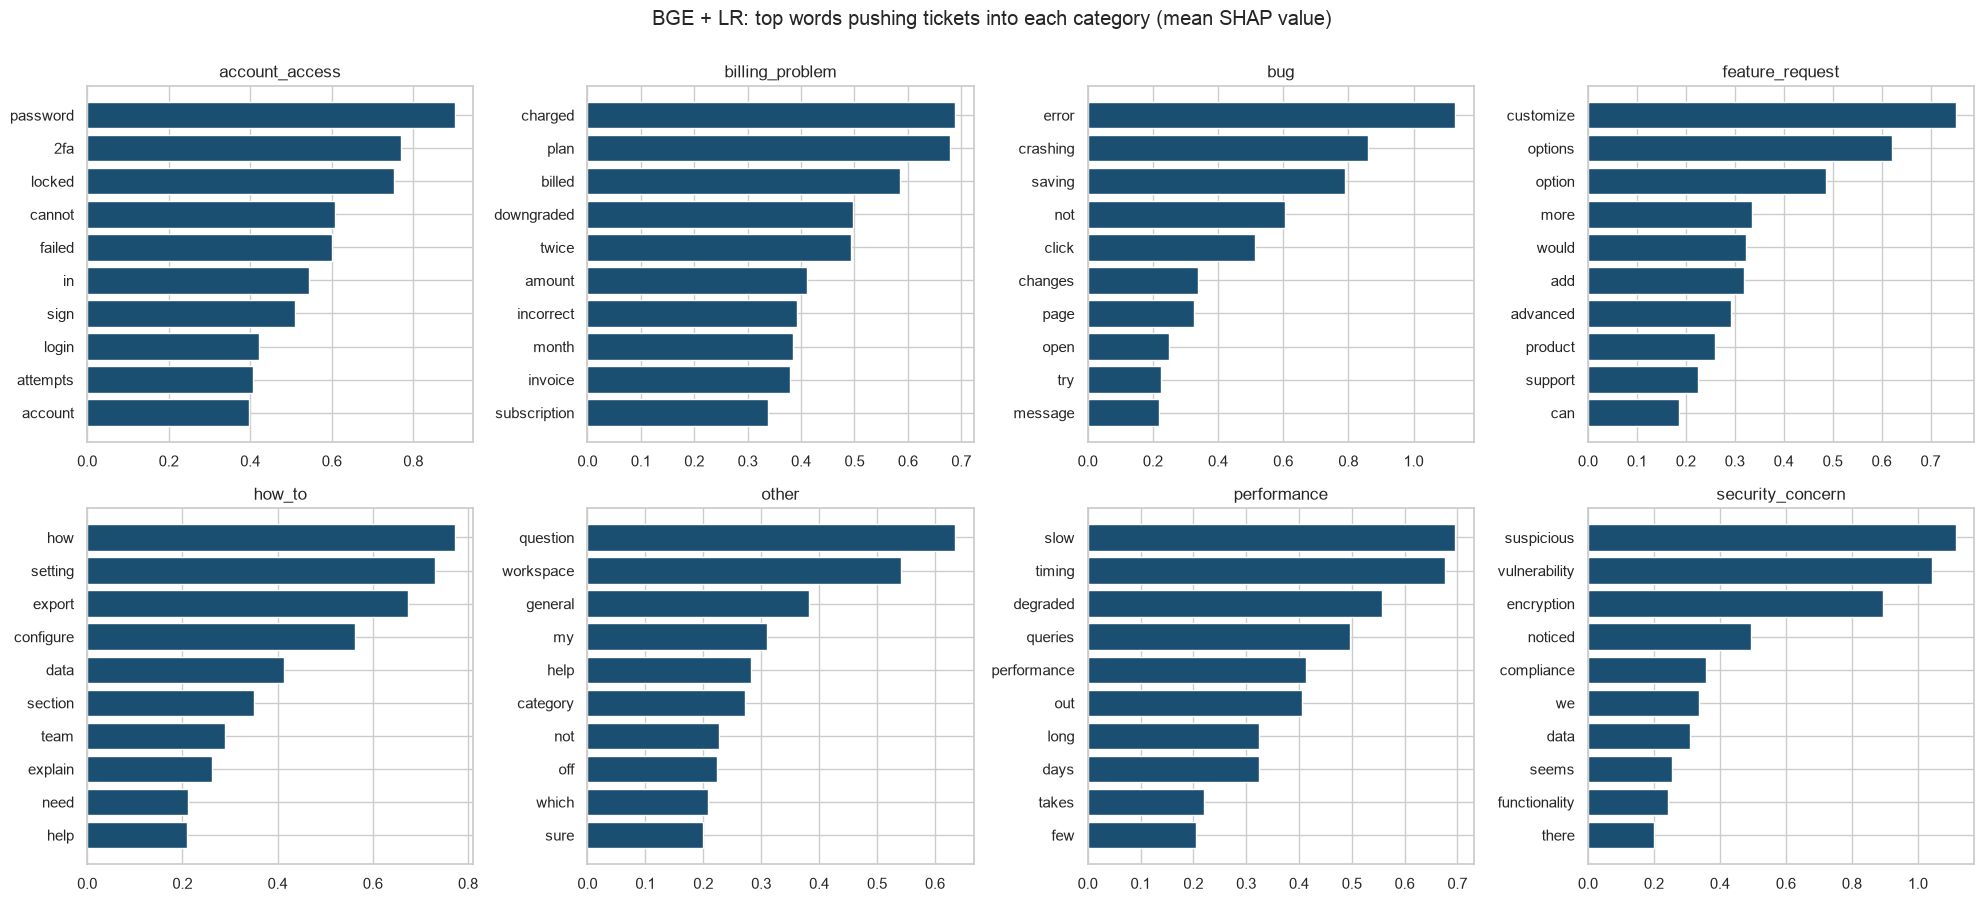

In [5]:
clean = lambda w: re.sub(r"[^\w']", "", w.lower())

long_rows = []        # one row per (message, word, category)
for (_, row), r in zip(unique.iterrows(), results):
    for j, w in enumerate(r["words"]):
        for c_idx, c in enumerate(classes):
            long_rows.append({"msg": row[TEXT], "true": row[TARGET], "tickets": row["tickets"], "position": j,
                              "word": clean(w), "category": c, "shap": r["phi"][j, c_idx]})
long = pd.DataFrame(long_rows)

own = long[long["true"] == long["category"]].copy()                # contributions towards each message's true category
own["weighted"] = own["shap"] * own["tickets"]
cat_tickets = unique.groupby(TARGET)["tickets"].sum()
mean_shap = own.groupby(["category", "word"])["weighted"].sum().div(cat_tickets.rename_axis("category"), level="category")
shap_bge_global = (mean_shap.rename("mean_shap").reset_index()
                   .query("mean_shap > 0").sort_values(["category", "mean_shap"], ascending=[True, False])
                   .groupby("category").head(10).rename(columns={"word": "term"}).reset_index(drop=True))

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), classes):
    d = shap_bge_global[shap_bge_global["category"] == c].sort_values("mean_shap")
    ax.barh(d["term"], d["mean_shap"], color="#1b4f72")
    ax.set_title(c)
plt.suptitle("BGE + LR: top words pushing tickets into each category (mean SHAP value)", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "33_shap_bge_global.png"); plt.show()

In every category, the **top 3 words are words a human agent would look for**:

- **account_access:** password, 2fa, locked (then cannot, failed, sign in)
- **billing_problem:** charged, plan, billed, downgraded, twice
- **bug:** error, crashing, saving, not (as in "not saving")
- **feature_request:** customize, options, option
- **how_to:** how, setting, export, configure
- **other:** question, workspace, general
- **performance:** slow, timing, degraded, queries
- **security_concern:** suspicious, vulnerability, encryption

In notebook 03, filler words such as "after", "in the" and "are" made the TF-IDF top lists. Filler words still appear lower down here ("my" for other, "we" for security_concern), but none reaches a top 3.

### Do filler words still matter? Comparison with the TF-IDF model

Notebook 03 found that the TF-IDF model leans on filler words ("my", "the", "in the", "after"). Here we compare both models on the same footing:
for every message we take the SHAP values of the **words that are in the message**, towards the **predicted** category, and measure how much of the total
(absolute) contribution goes to **stop words** (common words such as "the", "my", "after", "in" from scikit-learn's English list).
For TF-IDF a word pair counts as a stop word only if both words are stop words.

In [6]:
# TF-IDF model, exact linear SHAP as in notebook 03 (only features present in the message)
tfidf_model = joblib.load(config.MODELS / "tfidf_logreg.joblib")
tfidf = tfidf_model.named_steps["tfidfvectorizer"]
tf_clf = tfidf_model.named_steps["logisticregression"]
terms = tfidf.get_feature_names_out()
background = np.load(config.MODELS / "shap_background.npy")
is_stop_term = np.array([all(t in ENGLISH_STOP_WORDS for t in term.split()) for term in terms])

rows = []
for (_, row), r in zip(unique.iterrows(), results):
    x = tfidf.transform([row[TEXT]]).toarray()[0]
    c = int(np.argmax(tf_clf.decision_function(x[None])[0]))
    present = x > 0
    contrib = np.abs((x - background) * tf_clf.coef_[c])[present]
    tf_share = contrib[is_stop_term[present]].sum() / contrib.sum()

    c = classes.index(r["pred"])
    vals = np.abs(r["phi"][:, c])
    stop = np.array([clean(w) in ENGLISH_STOP_WORDS for w in r["words"]])
    rows.append({"tickets": row["tickets"], "TF-IDF + LR": tf_share, "BGE + LR": vals[stop].sum() / vals.sum(),
                 "stop-word share of the words": stop.mean()})
stop_share = pd.DataFrame(rows)
summary_stop = stop_share.drop(columns="tickets").apply(lambda col: np.average(col, weights=stop_share["tickets"]))
print("Share of the explanation that goes to stop words (ticket-weighted):")
print(summary_stop.map("{:.0%}".format).to_string())

Share of the explanation that goes to stop words (ticket-weighted):
TF-IDF + LR                     27%
BGE + LR                        26%
stop-word share of the words    52%


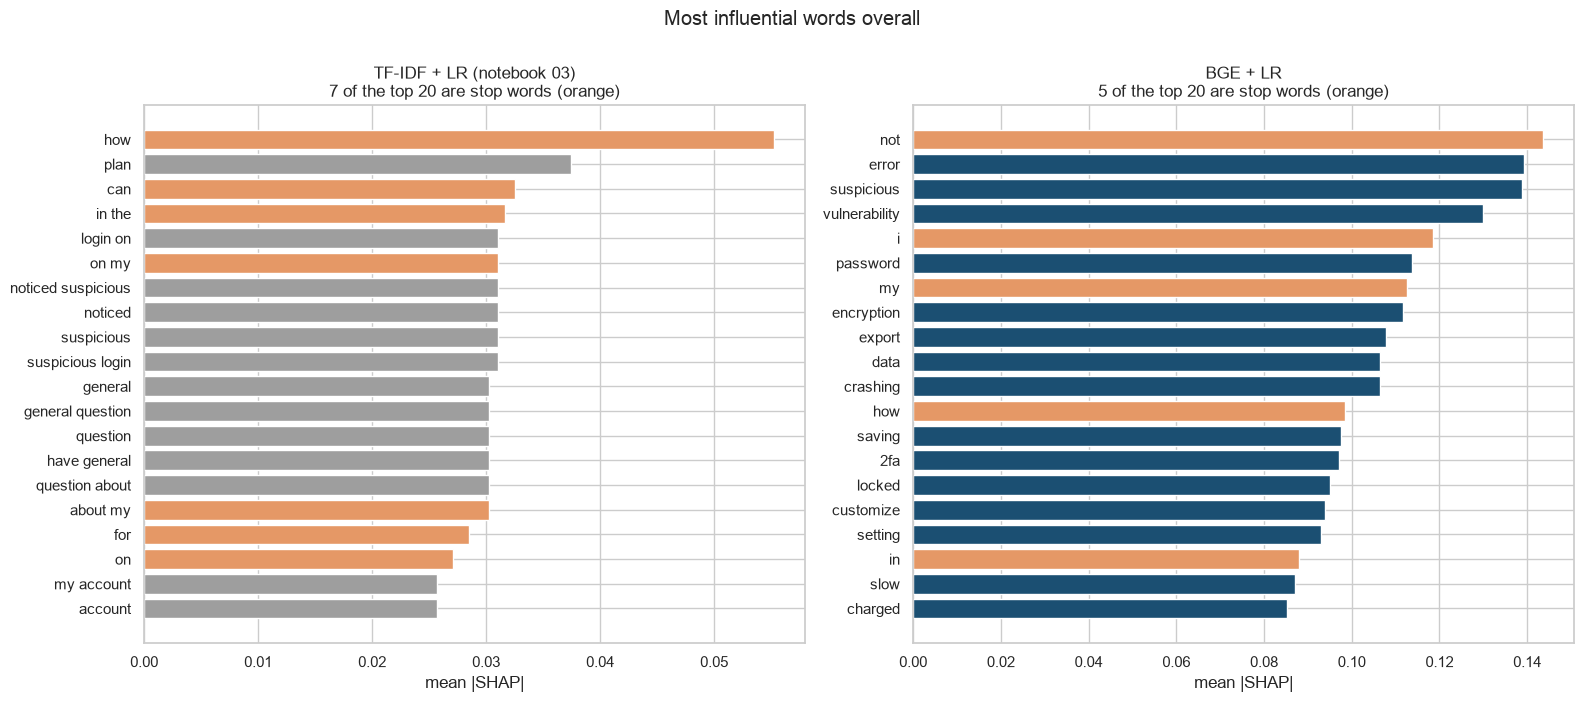

In [7]:
# Most influential words overall, both models (mean |SHAP| towards the predicted category, words present in the message, ticket-weighted)
pred_of = {m: r["pred"] for m, r in zip(unique[TEXT], results)}
bge_pred = long[long["category"] == long["msg"].map(pred_of)].copy()
bge_overall = (bge_pred.assign(w=bge_pred["shap"].abs() * bge_pred["tickets"]).groupby("word")["w"].sum() / unique["tickets"].sum())

tf_rows = []
for _, row in unique.iterrows():
    x = tfidf.transform([row[TEXT]]).toarray()[0]
    c = int(np.argmax(tf_clf.decision_function(x[None])[0]))
    present = np.where(x > 0)[0]
    contrib = np.abs((x - background) * tf_clf.coef_[c])
    tf_rows += [{"term": terms[j], "w": contrib[j] * row["tickets"]} for j in present]
tf_overall = pd.DataFrame(tf_rows).groupby("term")["w"].sum() / unique["tickets"].sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, s, colour) in zip(axes, [("TF-IDF + LR (notebook 03)", tf_overall, "#9e9e9e"), ("BGE + LR", bge_overall, "#1b4f72")]):
    top = s.sort_values(ascending=False).head(20).sort_values()
    is_stop = [all(t in ENGLISH_STOP_WORDS for t in term.split()) for term in top.index]
    ax.barh(top.index, top.values, color=["#e59866" if st else colour for st in is_stop])
    ax.set_title(f"{name}\n{sum(is_stop)} of the top 20 are stop words (orange)")
    ax.set_xlabel("mean |SHAP|")
plt.suptitle("Most influential words overall", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "34_shap_bge_overall.png"); plt.show()

- **Overall, both models lean on stop words about equally:** 27% of the explanation for TF-IDF and 26% for BGE, while about half of all words in the messages are stop words. BGE does **not** simply ignore common words.
- The difference is **which words carry the most weight** (chart):
  - TF-IDF's top 20 is dominated by word pairs from the three one-off sentences ("suspicious login", "general question", "about my", "on my"), plus "how", "can" and "in the".
  - BGE's top 20 is mostly problem words: error, suspicious, vulnerability, password, encryption, crashing, saving, 2fa, locked, slow, charged.
- Some of BGE's stop words carry meaning in context:
  - "not" (as in "not saving", "not working") is its single most influential word.
  - "how" marks how-to questions.
  - "in" comes from "sign in".
- "I" and "my" are true filler. The synthetic templates differ in whether they are written in the first person, and the model picks that up. This is the same dataset limitation notebook 03 described.

## 3. Local view: why did this ticket get this prediction?

The same four new sentences as notebook 03 (written by us, not in the dataset), plus the lockout sentence that TF-IDF got wrong.
For each one we show both models' predictions, then the BGE explanation towards its predicted category.

,message,TF-IDF + LR,BGE + LR
0,I was charged twice for my subscription this month.,billing_problem (99%),billing_problem (99%)
1,Locked out of my account after entering the wrong password too many times,account_access (66%),account_access (98%)
2,The export page crashes and the invoice is wrong,performance (37%),bug (69%)
3,How do I reset my password?,account_access (40%),account_access (92%)
4,My account was locked after multiple failed login attempts.,account_access (99%),account_access (99%)


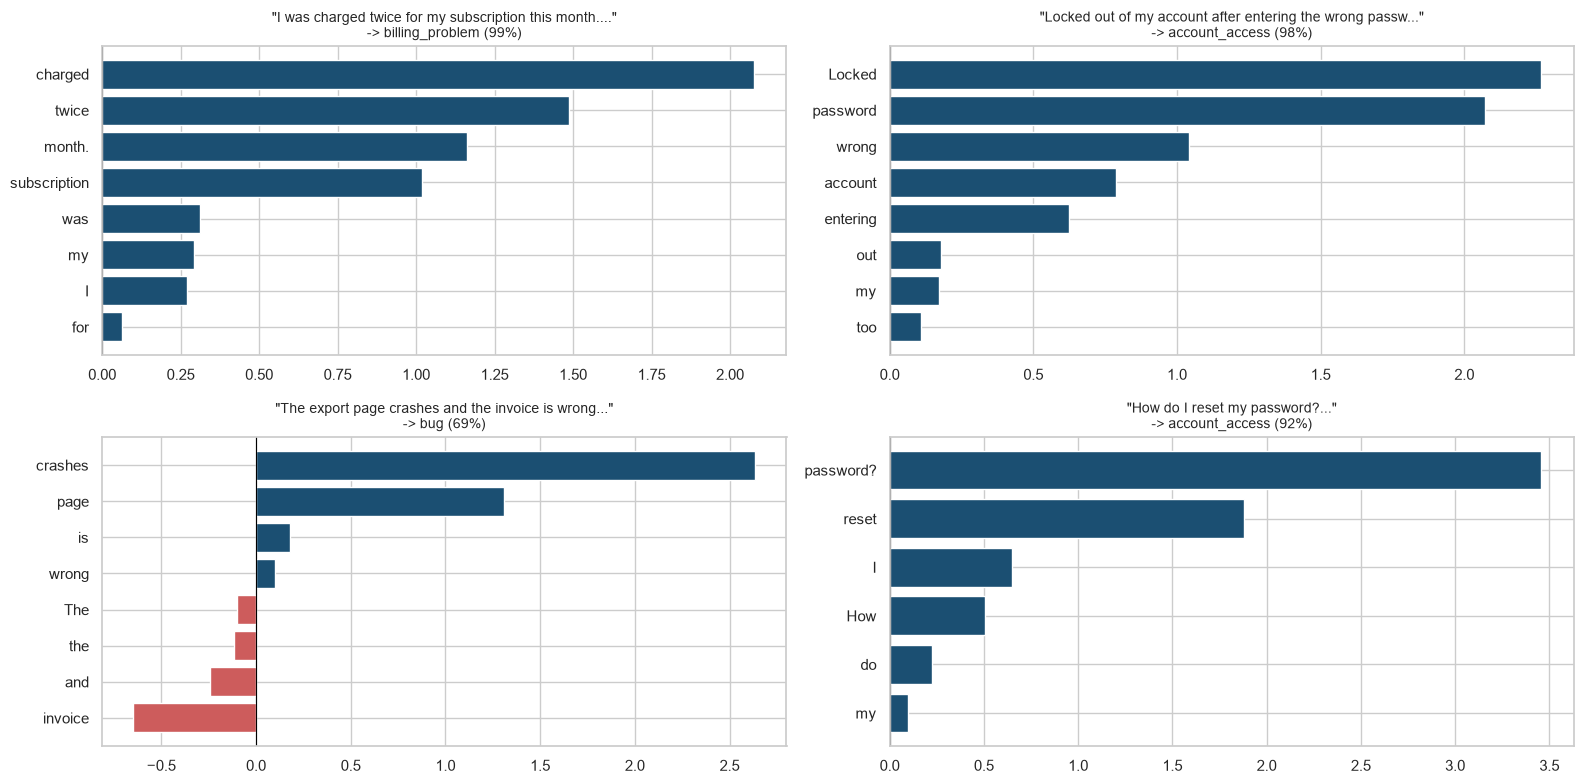

In [8]:
def explain(text, top_n=8):
    words, phi, base, full = exact_shap(text)
    proba = softmax(full)
    c = int(proba.argmax())
    table = pd.DataFrame({"term": words, "shap": phi[:, c]})
    table = table.reindex(table["shap"].abs().sort_values(ascending=False).index).head(top_n)
    return classes[c], proba[c], table

samples = [
    "I was charged twice for my subscription this month.",
    "Locked out of my account after entering the wrong password too many times",
    "The export page crashes and the invoice is wrong",
    "How do I reset my password?",
    "My account was locked after multiple failed login attempts.",
]
compare = []
for text in samples:
    label, conf, _ = explain(text)
    p = tfidf_model.predict_proba([text])[0]
    compare.append({"message": text, "TF-IDF + LR": f"{tfidf_model.classes_[p.argmax()]} ({p.max():.0%})",
                    "BGE + LR": f"{label} ({conf:.0%})"})
display(pd.DataFrame(compare))

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, text in zip(axes.ravel(), samples[:4]):
    label, conf, table = explain(text)
    table = table.sort_values("shap")
    ax.barh(table["term"], table["shap"], color=np.where(table["shap"] > 0, "#1b4f72", "indianred"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"\"{text[:55]}...\"\n-> {label} ({conf:.0%})", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "35_shap_bge_local.png"); plt.show()

- **"Charged twice":** both models are sure (99%). BGE relies on "charged", "twice", "month" and "subscription".
- **New wording for the lockout:** confidence rises from 66% (TF-IDF) to **98%** (BGE). "Locked", "password", "wrong" and "entering" drive it. They mean the same as the training sentence even though the wording differs.
- **"The export page crashes and the invoice is wrong":**
  - TF-IDF guessed performance (37%). BGE says **bug (69%)** because of "crashes" and "page", while "invoice" pulls the other way.
  - The ticket really mixes two problems. At 69% it would be auto-routed to the bug team even though half of it is a billing issue. That is a limit of giving each ticket a single label, and the explanation makes it visible.
- **"How do I reset my password?":** TF-IDF was unsure (40%, so manual review). BGE is confident (**92%** account_access), driven by "password" and "reset". That's a reasonable call, though some teams would file it as how_to.

## 4. Are the explanations faithful? A deletion test

If SHAP really finds the words the model relies on, deleting the top SHAP words should hurt the prediction much more than deleting random words.
For each of the 96 messages we delete the 1, 2 or 3 words with the highest SHAP value towards the predicted category, and compare with deleting
the same number of random words (average of 20 random draws). We measure how much the probability of the original prediction drops.

In [9]:
rng = np.random.default_rng(SEED)
def proba_of(texts, c):
    return np.array([softmax(s)[c] for s in scores(texts)])

rows = []
for r in results:
    c = classes.index(r["pred"])
    words, order = r["words"], np.argsort(-r["phi"][:, c])
    for k in (1, 2, 3):
        drop_top = " ".join(w for j, w in enumerate(words) if j not in set(order[:k]))
        rand = [" ".join(w for j, w in enumerate(words) if j not in set(rng.choice(len(words), k, replace=False))) for _ in range(20)]
        rows.append({"words deleted": k,
                     "top SHAP words": r["confidence"] - proba_of([drop_top], c)[0],
                     "random words": r["confidence"] - proba_of(rand, c).mean(),
                     "prediction changed (top SHAP)": classes[int(np.argmax(scores([drop_top])[0]))] != r["pred"]})
deletion = pd.DataFrame(rows).groupby("words deleted").mean()
deletion

,top SHAP words,random words,prediction changed (top SHAP)
words deleted,,,
1,0.124844,0.025728,0.010417
2,0.294587,0.061884,0.145833
3,0.519251,0.118080,0.406250


- Deleting the single top-SHAP word lowers the confidence of the original prediction by **12 points** on average, vs **3 points** for a random word, about 5 times more.
- Deleting the top 3 SHAP words lowers it by **52 points** (vs 12 for random words) and changes the prediction for **41%** of messages.
- So the explanations point to words the model really depends on. They aren't just plausible-looking.

## 5. Save the explanations

Same file layout as notebook 03 (`shap_global.csv`, `shap_local.csv`), so the dashboard could switch to them.

In [10]:
local_rows = []
for (_, row), r in zip(unique.iterrows(), results):
    c = classes.index(r["pred"])
    order = np.argsort(-np.abs(r["phi"][:, c]))[:8]
    for j in order:
        local_rows.append({TEXT: row[TEXT], "predicted": r["pred"], "confidence": r["confidence"],
                           "term": r["words"][j], "shap": r["phi"][j, c]})
shap_bge_local = pd.DataFrame(local_rows)

shap_bge_global.to_csv(config.PROCESSED / "shap_bge_global.csv", index=False)
shap_bge_local.to_csv(config.PROCESSED / "shap_bge_local.csv", index=False)
pd.DataFrame(compare).to_csv(config.PROCESSED / "shap_bge_examples.csv", index=False)
deletion.reset_index().to_csv(config.PROCESSED / "shap_bge_deletion_test.csv", index=False)
pd.concat([tf_overall.sort_values(ascending=False).head(20).rename_axis("term").reset_index(name="mean_abs_shap").assign(model="TF-IDF + LR"),
           bge_overall.sort_values(ascending=False).head(20).rename_axis("term").reset_index(name="mean_abs_shap").assign(model="BGE + LR")]
          ).to_csv(config.PROCESSED / "shap_overall_comparison.csv", index=False)
json.dump({"additivity_max_error": float(err),
           "shap_library_max_difference": float(max(diffs)) if "diffs" in globals() else None,
           "stop_word_share_tfidf": float(summary_stop["TF-IDF + LR"]), "stop_word_share_bge": float(summary_stop["BGE + LR"]),
           "stop_word_share_of_words": float(summary_stop["stop-word share of the words"]),
           "messages_explained": len(results), "sentences_embedded": len(score_cache)},
          open(config.PROCESSED / "shap_bge_checks.json", "w"), indent=2)
print("Saved shap_bge_global.csv:", shap_bge_global.shape, "| shap_bge_local.csv:", shap_bge_local.shape,
      "| shap_bge_examples.csv, shap_bge_deletion_test.csv, shap_overall_comparison.csv, shap_bge_checks.json")

Saved shap_bge_global.csv: (80, 3) | shap_bge_local.csv: (768, 5) | shap_bge_examples.csv, shap_bge_deletion_test.csv, shap_overall_comparison.csv, shap_bge_checks.json


## Summary

| | Notebook 03 (TF-IDF + LR) | Notebook 3b (BGE + LR) |
|---|---|---|
| Method | exact linear SHAP on TF-IDF features | exact Shapley values over words (each word deleted and the sentence re-embedded) |
| Additivity check (largest error) | 2e-14 | 4e-8 (float precision of the embedding model) |
| Matches the `shap` library | not checked (not installed) | yes, within 1e-8 |
| Top words per category | mostly key words, some filler in the top lists ("after", "in the") | key words in every top 3 |
| Stop-word share of the explanation | 27% | 26% |
| Deletion test | – | the top word matters about 5 times more than a random word |
| Cost | instant | ~4 minutes for all 96 messages on an Apple GPU; a few seconds for one new ticket |

**Limitations**
- Each word gets its own value. When words only work together ("not" + "saving", "sign" + "in"), the Shapley rule splits the credit between them.
- Trying every subset of words only works for short messages (2<sup>n</sup> versions). For long real tickets, use a sampling explainer such as `shap`'s Permutation or Partition explainer.
- Removing a word can produce ungrammatical text. That is standard for text SHAP, but it means the model is sometimes scored on sentences it would never see.

**Saved:** `data/processed/shap_bge_global.csv` and `shap_bge_local.csv` (same layout as notebook 03's files), plus `shap_bge_examples.csv`, `shap_bge_deletion_test.csv`, `shap_overall_comparison.csv` and `shap_bge_checks.json`, figures `33`–`35`. The dashboard still shows the TF-IDF explanations from notebook 03.